# Machine Learning Laboratory · 03
## Regularisation, early stopping and model selection

Experiments for **slides L2-S61–L2-S80**. This notebook is self-contained:
run it in a fresh kernel; no earlier notebook or saved result is required.

[All notebooks and setup](NOTEBOOK_README.md) · [Practical exercises](exercises/README.md)

Install `requirements-notebook.txt`, then select **Restart Kernel and Run All Cells**.
Saved static plots are visible on GitHub. Python 3.11+; CPU / float64.

**Question:** how do we compare penalties and architectures without using the
final test set to make those decisions?

In [1]:
import copy, io, json, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Image

SEED = 4
RUN_MODE = "quick"                 # "quick" or "thorough"
assert RUN_MODE in {"quick", "thorough"}
FACTOR = 1 if RUN_MODE == "quick" else 2
START = time.perf_counter()
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
versions = dict(python=platform.python_version(), numpy=np.__version__,
                matplotlib=matplotlib.__version__, torch=torch.__version__)
print(json.dumps(versions, indent=2))
print(f"CPU / float64 / seed {SEED} / {RUN_MODE} mode")

palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 110, "legend.frameon": False,
    "font.family": "DejaVu Sans",
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "pink", "blue", "navy"]]),
})

def show_figure(fig):
    """Embed a compact static PNG so GitHub can display the result."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def signal(x):
    return np.sin(np.pi*x)

def sample_data(generator, n, sigma=0.05):
    x = np.sort(generator.uniform(0, 1, n))[:, None]
    y = signal(x) + sigma*generator.normal(size=x.shape)
    return x, y

def make_mlp(width=16, depth=2):
    layers = [nn.Linear(1, width), nn.Tanh()]
    for _ in range(depth-1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    return nn.Sequential(*layers, nn.Linear(width, 1))

{
  "python": "3.13.9",
  "numpy": "2.4.2",
  "matplotlib": "3.10.8",
  "torch": "2.10.0"
}
CPU / float64 / seed 4 / quick mode


## 1 · L1, L2 and elastic net on a problem we can solve exactly

For the deliberately normalised objective
$$\tfrac12\|b-z\|_2^2+\lambda_1\|b\|_1+\tfrac{\lambda_2}{2}\|b\|_2^2,$$
the minimiser is $b_j=\operatorname{sign}(z_j)\max(|z_j|-\lambda_1,0)/(1+\lambda_2)$.
L1 can create exact zeros; L2 shrinks continuously. The factor $1/2$ here matters:
the threshold changes if the squared-loss normalisation changes. This is an
orthogonal toy problem, not a formula for arbitrary correlated regression features.

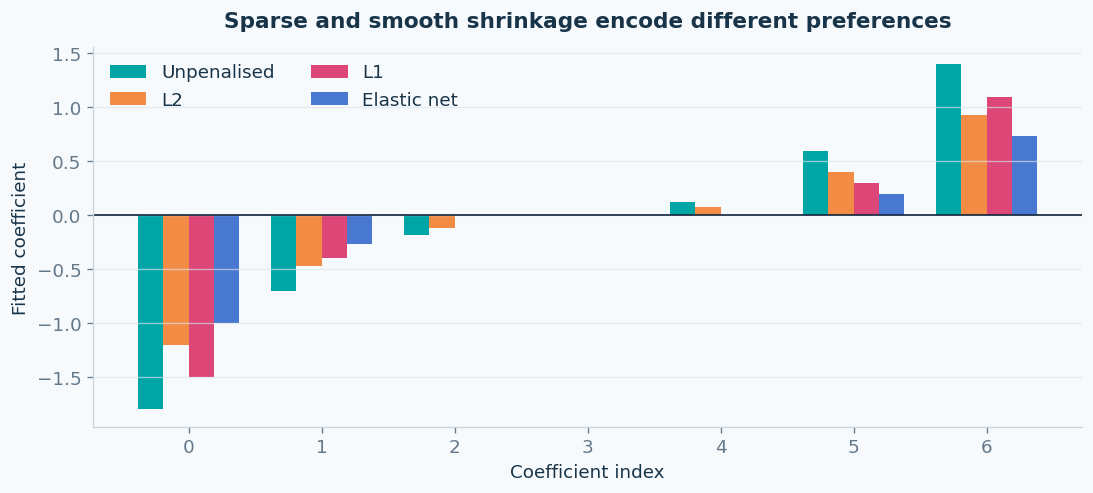

In [2]:
z = np.array([-1.8, -.7, -.18, 0., .12, .6, 1.4])
def shrink(z, lambda1=0., lambda2=0.):
    return np.sign(z)*np.maximum(np.abs(z)-lambda1, 0)/(1+lambda2)
penalties = {"Unpenalised": z, "L2": shrink(z, 0, .5),
             "L1": shrink(z, .3, 0), "Elastic net": shrink(z, .3, .5)}
assert np.count_nonzero(shrink(z, .3, 0)) == 4
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
positions = np.arange(len(z))
for i, (name, coefficients) in enumerate(penalties.items()):
    ax.bar(positions+(i-1.5)*.19, coefficients, .19, label=name)
ax.axhline(0, color=palette["navy"], lw=1)
ax.set(xticks=positions, xlabel="Coefficient index", ylabel="Fitted coefficient",
       title="Sparse and smooth shrinkage encode different preferences")
ax.legend(ncol=2); ax.grid(axis="y")
show_figure(fig)

## 2 · Select ridge strength using validation data

We increase the noise to $\sigma=0.15$ and use only 24 training observations.
A degree-16 Legendre expansion is flexible enough to amplify noise. The objective is
$$\frac1N\|A\beta-y\|_2^2+\frac\lambda2\sum_{j=1}^{16}\beta_j^2.$$
The constant coefficient is unpenalised. We solve an augmented least-squares system,
whose extra rows are $\sqrt{N\lambda/2}\operatorname{diag}(0,1,\ldots,1)$.

The candidate list is fixed now. Validation MSE selects its penalty. Test data are
created and evaluated only in the final assessment cell after **both** model families
have been frozen. Comparing many candidates can itself overfit a validation set.

    lambda    train MSE   validation MSE   slope norm
         0     0.006234   4262113.608724   4079.63558
     1e-05     0.007890         0.881945      3.53174
     0.001     0.008218         0.061411      0.88890
      0.01     0.008595         0.051790      0.75674
       0.1     0.013771         0.044903      0.56775
       0.5     0.038399         0.063314      0.34563
Selected ridge lambda: 0.1


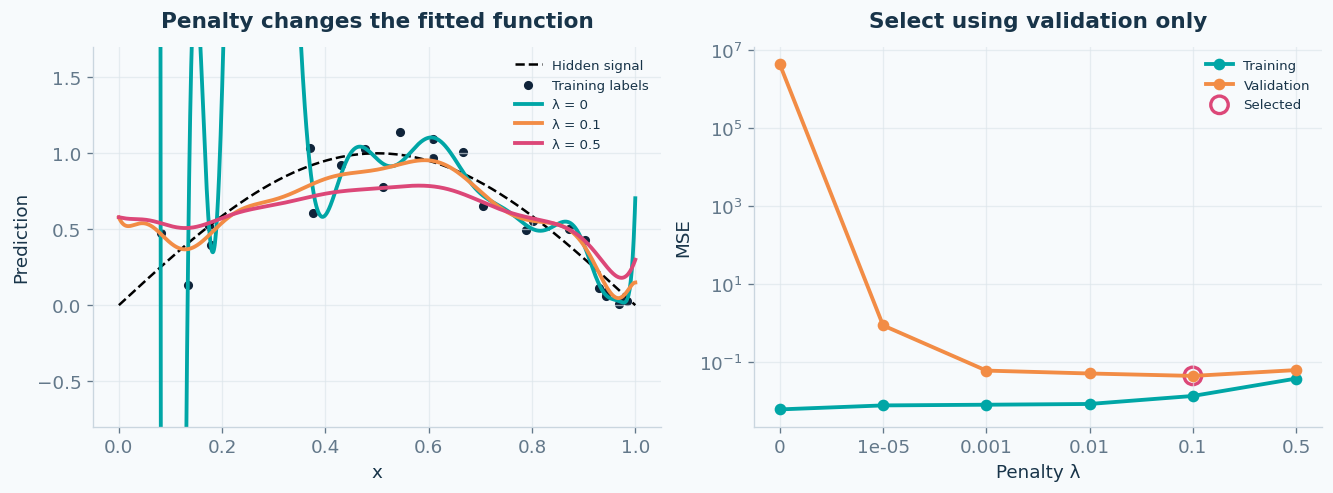

Prediction plot has fixed y-limits for readability; numerical scores include all predictions.


In [3]:
sigma = .15
train_x, train_y = sample_data(np.random.default_rng(SEED), 24, sigma)
validation_x, validation_y = sample_data(np.random.default_rng(SEED+1), 128, sigma)
degree = 16
def design(x):
    return np.polynomial.legendre.legvander(2*np.asarray(x).reshape(-1)-1, degree)
A, VA = design(train_x), design(validation_x)
penalty_matrix = np.diag(np.r_[0., np.ones(degree)])
strengths = [0., 1e-5, 1e-3, .01, .1, .5]
ridge_fits, ridge_rows = [], []
for strength in strengths:
    augmented_A = np.vstack([A, np.sqrt(len(A)*strength/2)*penalty_matrix])
    augmented_y = np.r_[train_y[:, 0], np.zeros(degree+1)]
    coefficient, *_ = np.linalg.lstsq(augmented_A, augmented_y, rcond=None)
    training_mse = np.mean((A @ coefficient-train_y[:, 0])**2)
    validation_mse = np.mean((VA @ coefficient-validation_y[:, 0])**2)
    ridge_fits.append(coefficient)
    ridge_rows.append((strength, training_mse, validation_mse, np.linalg.norm(coefficient[1:])))
ridge_choice = int(np.argmin([row[2] for row in ridge_rows]))
ridge_coefficient = ridge_fits[ridge_choice].copy()
print(f"{'lambda':>10s} {'train MSE':>12s} {'validation MSE':>16s} {'slope norm':>12s}")
for row in ridge_rows:
    print(f"{row[0]:10.5g} {row[1]:12.6f} {row[2]:16.6f} {row[3]:12.5f}")
print("Selected ridge lambda:", strengths[ridge_choice])
xgrid = np.linspace(0, 1, 1001)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(xgrid, signal(xgrid), "k--", lw=1.5, label="Hidden signal")
axes[0].scatter(train_x, train_y, s=20, color=palette["navy"], label="Training labels")
for index in sorted({0, ridge_choice, len(strengths)-1}):
    axes[0].plot(xgrid, design(xgrid) @ ridge_fits[index], label=f"λ = {strengths[index]:g}")
axes[0].set(xlabel="x", ylabel="Prediction", ylim=(-.8, 1.7), title="Penalty changes the fitted function")
axes[1].plot(np.arange(len(strengths)), [r[1] for r in ridge_rows], "o-", label="Training")
axes[1].plot(np.arange(len(strengths)), [r[2] for r in ridge_rows], "o-", label="Validation")
axes[1].scatter([ridge_choice], [ridge_rows[ridge_choice][2]], s=110, facecolors="none",
                edgecolors=palette["pink"], linewidths=2, label="Selected")
axes[1].set(xticks=np.arange(len(strengths)), xticklabels=[f"{v:g}" for v in strengths],
            xlabel="Penalty λ", ylabel="MSE", yscale="log", title="Select using validation only")
for ax in axes:
    ax.legend(fontsize=8); ax.grid()
show_figure(fig)
print("Prediction plot has fixed y-limits for readability; numerical scores include all predictions.")

## 3 · Width, depth, repeated seeds and copied checkpoints

Compare three predeclared MLP architectures on the same train/validation split, using
three initialisation seeds and an equal number of full-batch updates. Save the lowest
validation-loss checkpoint **by value** with `copy.deepcopy(model.state_dict())`.
A reference to the live state would continue changing during training.

We rank architectures by the mean best-checkpoint validation MSE across seeds.
The final neural predictor is the average of all three restored models for the chosen
architecture; a seed is not selected using test performance. Equal update counts
are not equal compute costs. These few seeds describe initialisation variability,
not uncertainty over new training datasets.

width  8, depth 1: parameters   25 | validation 0.03077 ± 0.00403 (seed SD) | checkpoints [357, 304, 459]


width 16, depth 2: parameters  321 | validation 0.02856 ± 0.00051 (seed SD) | checkpoints [284, 201, 231]


width 32, depth 2: parameters 1153 | validation 0.03053 ± 0.00106 (seed SD) | checkpoints [145, 509, 532]


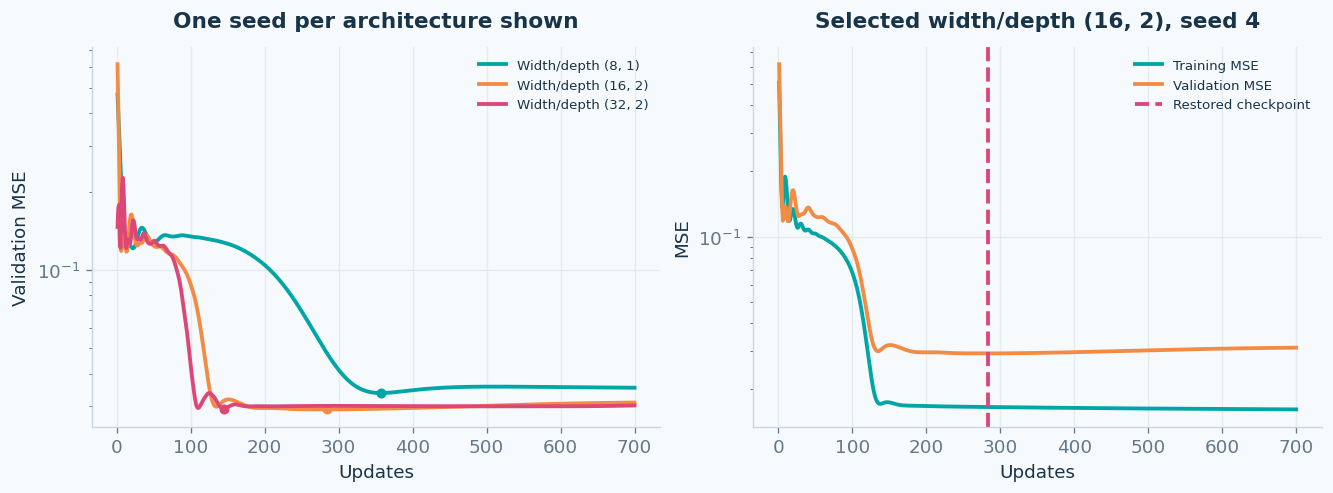

Selected architecture: (16, 2)


In [4]:
X, Y = torch.tensor(train_x), torch.tensor(train_y)
VX, VY = torch.tensor(validation_x), torch.tensor(validation_y)
architectures = [(8, 1), (16, 2), (32, 2)]
initialisation_seeds = [4, 14, 24]
steps = 700*FACTOR
neural_runs = {}
for width, depth in architectures:
    runs = []
    for seed in initialisation_seeds:
        torch.manual_seed(seed)
        model = make_mlp(width, depth)
        optimizer = torch.optim.Adam(model.parameters(), lr=.01)
        best_value, best_epoch, best_state = float("inf"), None, None
        history = []
        for epoch in range(1, steps+1):
            model.train()
            optimizer.zero_grad(set_to_none=True)
            training_loss = (model(X)-Y).square().mean()
            training_loss.backward()
            optimizer.step()
            model.eval()
            with torch.no_grad():
                train_value = (model(X)-Y).square().mean().item()
                validation_value = (model(VX)-VY).square().mean().item()
            history.append((train_value, validation_value))
            if validation_value < best_value:
                best_value, best_epoch = validation_value, epoch
                best_state = copy.deepcopy(model.state_dict())
        model.load_state_dict(best_state)
        with torch.no_grad():
            restored_value = (model(VX)-VY).square().mean().item()
        assert np.isclose(restored_value, best_value, rtol=1e-12, atol=1e-14)
        runs.append(dict(model=model, history=np.array(history), best_validation=best_value,
                         best_epoch=best_epoch, seed=seed))
    neural_runs[(width, depth)] = runs
    scores = np.array([r["best_validation"] for r in runs])
    print(f"width {width:2d}, depth {depth}: parameters {sum(p.numel() for p in runs[0]['model'].parameters()):4d}"
          f" | validation {scores.mean():.5f} ± {scores.std(ddof=1):.5f} (seed SD)"
          f" | checkpoints {[r['best_epoch'] for r in runs]}")
selected_architecture = min(architectures, key=lambda architecture:
                           np.mean([r["best_validation"] for r in neural_runs[architecture]]))
selected_runs = neural_runs[selected_architecture]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for architecture, runs in neural_runs.items():
    first = runs[0]
    history = first["history"]
    line, = axes[0].semilogy(np.arange(1, steps+1), history[:, 1], label=f"Width/depth {architecture}")
    axes[0].scatter(first["best_epoch"], first["best_validation"], color=line.get_color(), s=25)
chosen = selected_runs[0]
axes[1].semilogy(np.arange(1, steps+1), chosen["history"][:, 0], label="Training MSE")
axes[1].semilogy(np.arange(1, steps+1), chosen["history"][:, 1], label="Validation MSE")
axes[1].axvline(chosen["best_epoch"], color=palette["pink"], ls="--", label="Restored checkpoint")
axes[0].set(title="One seed per architecture shown", xlabel="Updates", ylabel="Validation MSE")
axes[1].set(title=f"Selected width/depth {selected_architecture}, seed 4", xlabel="Updates", ylabel="MSE")
for ax in axes:
    ax.legend(fontsize=8); ax.grid()
show_figure(fig)
print("Selected architecture:", selected_architecture)

## 4 · Freeze both predictors, then assess on the test set

We now assess the validation-selected ridge model and neural ensemble as two
predeclared model families. The test result is a final report: it is not used to
change a penalty, architecture, epoch or seed. MSE and MAE have different units;
RMSE has the same units as the labels. A new decision informed by this report
would require a new independent test set for an unbiased final assessment.

In [5]:
test_x, test_y = sample_data(np.random.default_rng(SEED+1000), 1000, sigma)
TX = torch.tensor(test_x)
with torch.no_grad():
    ensemble_prediction = np.mean([r["model"](TX).numpy()[:, 0] for r in selected_runs], axis=0)
final_predictions = {"Selected ridge": design(test_x) @ ridge_coefficient,
                     "Selected neural ensemble": ensemble_prediction}
assessment = {}
for name, prediction in final_predictions.items():
    residual = prediction-test_y[:, 0]
    mse = float(np.mean(residual**2))
    assessment[name] = dict(mse=mse, rmse=float(np.sqrt(mse)), mae=float(np.mean(np.abs(residual))))
    print(f"{name:25s} | MSE {mse:.5f} | RMSE {np.sqrt(mse):.5f} | MAE {np.mean(np.abs(residual)):.5f}")
    assert np.isfinite(mse) and np.sqrt(mse) >= np.mean(np.abs(residual))-1e-12
record = dict(data_seed=SEED, sigma=sigma, split_sizes=[24, 128, 1000],
              initialisation_seeds=initialisation_seeds, updates_per_run=steps,
              ridge_degree=degree, selected_ridge_lambda=strengths[ridge_choice],
              selected_architecture=list(selected_architecture),
              checkpoint_epochs=[r["best_epoch"] for r in selected_runs],
              selection="mean validation MSE across initialisation seeds",
              final_neural_prediction="mean of restored selected-architecture models",
              assessment=assessment, versions=versions)
print(json.dumps(record, indent=2))
print(f"Notebook runtime: {time.perf_counter()-START:.1f} s")

Selected ridge            | MSE 0.04143 | RMSE 0.20354 | MAE 0.15619
Selected neural ensemble  | MSE 0.02887 | RMSE 0.16990 | MAE 0.13456
{
  "data_seed": 4,
  "sigma": 0.15,
  "split_sizes": [
    24,
    128,
    1000
  ],
  "initialisation_seeds": [
    4,
    14,
    24
  ],
  "updates_per_run": 700,
  "ridge_degree": 16,
  "selected_ridge_lambda": 0.1,
  "selected_architecture": [
    16,
    2
  ],
  "checkpoint_epochs": [
    284,
    201,
    231
  ],
  "selection": "mean validation MSE across initialisation seeds",
  "final_neural_prediction": "mean of restored selected-architecture models",
  "assessment": {
    "Selected ridge": {
      "mse": 0.04142721447346476,
      "rmse": 0.20353676442712937,
      "mae": 0.1561941946016842
    },
    "Selected neural ensemble": {
      "mse": 0.02886573724501256,
      "rmse": 0.16989919730538036,
      "mae": 0.13455667005868432
    }
  },
  "versions": {
    "python": "3.13.9",
    "numpy": "2.4.2",
    "matplotlib": "3.10.8",
    "

## Read the evidence

Penalty strength and stopping time both alter the selected predictor. A lower
training error alone cannot select either of them. The checkpoint test verifies
that the model we assess really is the one selected during training.

**Try:** reserve new assessment data before changing the candidate grid. Add an
explicit L2 term to the training objective, excluding biases if that is your stated
convention. Do not assume Adam weight decay and an explicit L2 loss are interchangeable
with decoupled AdamW weight decay. State precisely which objective you minimise.

Work through [practical 03](exercises/ML_Exercises_03_regularisation_and_evaluation.ipynb),
then continue to [Chapter 3](../3.%20Neural%20networks%20for%20solving%20PDEs/NOTEBOOK_README.md).